# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Walmar Wildan
- NIM   : 241011402756
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# NIM 241011402756 -> 2 digit terakhir = 56
RANDOM_STATE = 56

In [2]:
# Implementasi train_test_split (NumPy) -- disalin/disesuaikan dari materi
def train_test_split(X, y, test_size=0.25, random_state=None):
    """Membagi data menjadi train dan test secara acak (reproducible lewat random_state)."""
    X = np.asarray(X)
    y = np.asarray(y)
    n_samples = X.shape[0]
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(n_samples)          # acak urutan indeks
    n_test = int(round(n_samples * test_size))    # jumlah data test
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


# ------------------------------------------------------------------
# Model Linear Regression (dari materi)
# ------------------------------------------------------------------
class LinearRegression:
    """Linear Regression dengan Normal Equation: theta = (X^T X)^-1 X^T y"""
    def __init__(self):
        self.intercept_ = None
        self.coef_ = None

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        Xb = np.c_[np.ones(X.shape[0]), X]               # tambah kolom bias
        theta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y     # normal equation
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


class LinearRegressionGD:
    """Linear Regression dengan Gradient Descent (loss = MSE)"""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d)
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            y_pred = self.intercept_ + X @ self.coef_
            error = y_pred - y
            self.loss_history_.append(np.mean(error ** 2))   # MSE
            # gradien MSE terhadap b dan m
            grad_b = (2 / n) * np.sum(error)
            grad_m = (2 / n) * (X.T @ error)
            self.intercept_ -= self.learning_rate * grad_b
            self.coef_ -= self.learning_rate * grad_m
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


# ------------------------------------------------------------------
# Model Logistic Regression (dari materi)
# ------------------------------------------------------------------
def sigmoid(z):
    z = np.clip(z, -500, 500)       # hindari overflow pada exp
    return 1 / (1 + np.exp(-z))


class LogisticRegression:
    """Logistic Regression dengan Gradient Descent (loss = log loss)"""
    def __init__(self, learning_rate=0.1, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.intercept_ = 0.0
        self.coef_ = None
        self.loss_history_ = []

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d)
        self.loss_history_ = []
        eps = 1e-15
        for _ in range(self.n_iterations):
            p = sigmoid(self.intercept_ + X @ self.coef_)
            loss = -np.mean(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))
            self.loss_history_.append(loss)
            grad_b = np.mean(p - y)
            grad_m = (X.T @ (p - y)) / n
            self.intercept_ -= self.learning_rate * grad_b
            self.coef_ -= self.learning_rate * grad_m
        return self

    def predict_proba(self, X):
        X = np.asarray(X, dtype=float)
        return sigmoid(self.intercept_ + X @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


# ------------------------------------------------------------------
# Metrik klasifikasi dari materi
# ------------------------------------------------------------------
def accuracy_score(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))


def confusion_matrix(y_true, y_pred):
    """Mengembalikan [[TN, FP], [FN, TP]]"""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))
    return np.array([[tn, fp], [fn, tp]])

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 data pertama:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


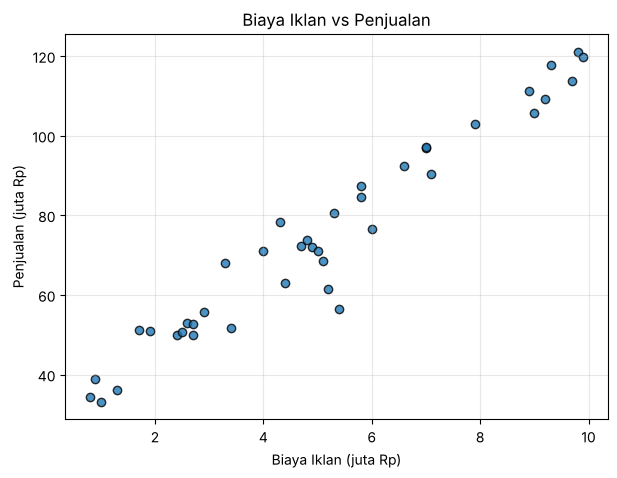

In [3]:
# Jawaban A1
# 1. Baca data
df_ads = pd.read_csv("Ads_Data.csv")
print("5 data pertama:")
display(df_ads.head())
print("Jumlah baris data:", len(df_ads))

# 2. Pisahkan X dan y (X harus 2 dimensi (n, 1))
X_ads = df_ads[["BiayaIklan"]].values      # kurung siku ganda -> 2D
y_ads = df_ads["Penjualan"].values
print("Shape X:", X_ads.shape, "| Shape y:", y_ads.shape)

# 3. Scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(X_ads, y_ads, color="tab:blue", edgecolor="k", alpha=0.8)
plt.title("Biaya Iklan vs Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [4]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [5]:
# Jawaban A3
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

b_ne = lin_reg.intercept_
m_ne = lin_reg.coef_[0]
print(f"Intercept (b)  : {b_ne:.4f}")
print(f"Koefisien (m)  : {m_ne:.4f}")
print(f"Persamaan      : y_hat = {b_ne:.4f} + {m_ne:.4f} * X")

Intercept (b)  : 28.5405
Koefisien (m)  : 8.9851
Persamaan      : y_hat = 28.5405 + 8.9851 * X


**Jawaban A3 (interpretasi):**

Persamaan regresi hasil training adalah $\hat{y} = 28.5405 + 8.9851\,X$.

Nilai $m = 8.9851$ berarti setiap kenaikan biaya iklan sebesar 1 juta Rp, rata-rata penjualan bulanan naik sekitar **8,99 juta Rp**. Dengan kata lain, setiap 1 juta yang diinvestasikan untuk iklan berasosiasi dengan kenaikan penjualan yang jauh lebih besar dari biayanya (hampir 9 kali lipat). Nilai intercept $b = 28.5405$ adalah perkiraan penjualan dasar (sekitar 28,5 juta Rp) ketika biaya iklan 0, misalnya dari pelanggan tetap atau penjualan organik. Perlu diingat bahwa hubungan ini hanya berupa asosiasi pada data yang ada, belum tentu hubungan sebab-akibat.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [6]:
# Jawaban A4
# Fungsi metrik regresi (implementasi sendiri dengan NumPy)
def mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def rmse(y_true, y_pred):
    return np.sqrt(mse(y_true, y_pred))

def r2_score(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - ss_res / ss_tot

y_pred_train = lin_reg.predict(X_train)
y_pred_test = lin_reg.predict(X_test)

hasil_eval = pd.DataFrame({
    "MAE":  [mae(y_train, y_pred_train),  mae(y_test, y_pred_test)],
    "MSE":  [mse(y_train, y_pred_train),  mse(y_test, y_pred_test)],
    "RMSE": [rmse(y_train, y_pred_train), rmse(y_test, y_pred_test)],
    "R2":   [r2_score(y_train, y_pred_train), r2_score(y_test, y_pred_test)],
}, index=["Training", "Testing"])
display(hasil_eval.round(4))
print("Rata-rata Penjualan (y) data testing:", round(y_test.mean(), 2))

,MAE,MSE,RMSE,R2
Training,5.1345,43.2469,6.5762,0.9276
Testing,2.2890,8.2377,2.8701,0.9873


Rata-rata Penjualan (y) data testing: 84.69


**Jawaban A4 (analisis):**

| | MAE | MSE | RMSE | R² |
|---|---|---|---|---|
| Training | 5.1345 | 43.2469 | 6.5762 | 0.9276 |
| Testing | 2.2890 | 8.2377 | 2.8701 | 0.9873 |

- **RMSE** mengukur besarnya kesalahan prediksi dalam satuan asli, yaitu juta Rp. RMSE testing 2,87 berarti ukuran kesalahan prediksi model sekitar 2,87 juta Rp (kira-kira 3,4% dari rata-rata penjualan data testing, 84,69 juta), sedangkan pada data training RMSE-nya 6,58 juta Rp. RMSE bukan rata-rata aritmetika dari kesalahan (itu adalah MAE). Karena kesalahan dikuadratkan terlebih dahulu sebelum dirata-rata dan diakarkan, RMSE **lebih sensitif terhadap kesalahan yang besar**: satu prediksi yang meleset jauh akan menaikkan RMSE lebih banyak daripada MAE. Pada hasil ini RMSE lebih besar daripada MAE (training 6,58 vs 5,13; testing 2,87 vs 2,29), yang menandakan ada beberapa kesalahan prediksi yang lebih besar dibanding yang lain.
- **R²** menyatakan proporsi variasi penjualan yang dapat dijelaskan oleh biaya iklan. R² training 0,9276 berarti sekitar 92,8% variasi penjualan dijelaskan oleh model, dan R² testing 0,9873 berarti sekitar 98,7%.
- **Kesimpulan:** model ini sudah baik karena R² di atas 0,92 pada kedua data, dan hubungan biaya iklan dengan penjualan memang tampak hampir linear pada scatter plot.
- Skor testing lebih tinggi daripada training. Ini tidak berarti model lebih bagus pada data baru. Data testing hanya 8 titik dan kebetulan titik-titik tersebut dekat dengan garis, sedangkan data training berisi beberapa titik yang menyimpang jauh dari garis (misalnya biaya iklan 3,4 dengan penjualan 51,7). Dengan data testing sekecil ini, angkanya sangat bergantung pada pembagian data. Gambaran yang lebih jujur adalah bahwa performa model berada di kisaran RMSE 3–7 juta dan R² 0,93–0,99.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

lr = 0.001  -> intercept = 25.7203, koefisien = 9.4412, loss akhir = 45.0734
lr = 0.02   -> intercept = 28.5405, koefisien = 8.9851, loss akhir = 43.2469


lr = 0.1    -> intercept = nan, koefisien = nan, loss akhir = nan

Normal Equation   -> intercept = 28.5405, koefisien = 8.9851


/tmp/ipykernel_201/1864301127.py:57: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean(error ** 2))   # MSE
/usr/local/lib/python3.13/dist-packages/numpy/_core/_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_201/1864301127.py:60: RuntimeWarning: overflow encountered in matmul
  grad_m = (2 / n) * (X.T @ error)
/tmp/ipykernel_201/1864301127.py:62: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * grad_m


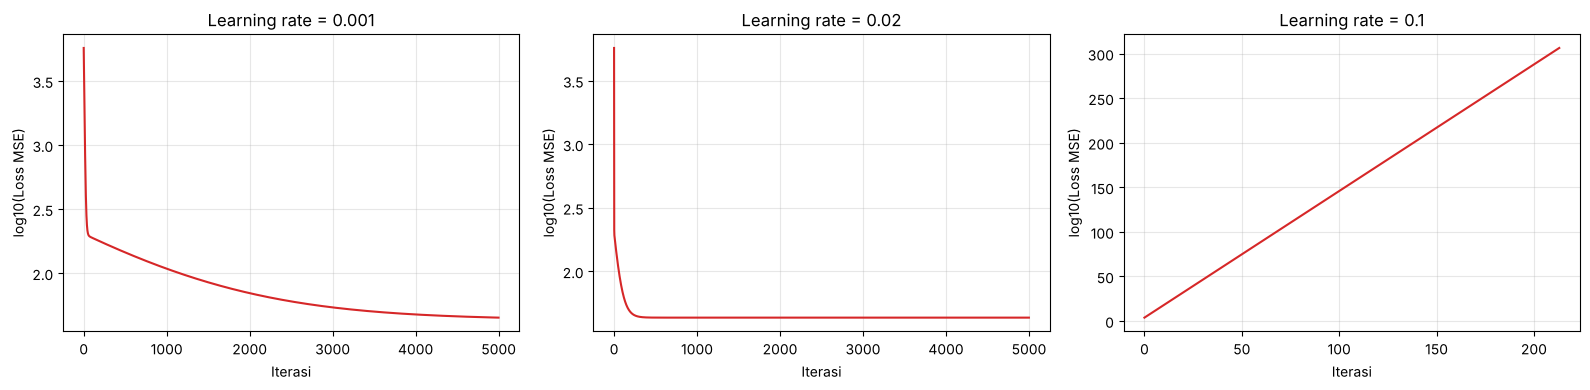

Loss lr=0.1: iterasi 0 = 5733.4 | iterasi 5 = 7.050e+10 | overflow (inf/nan) mulai iterasi ke- 214
Eigenvalue terbesar Hessian = 61.35 -> learning rate maksimum yang stabil = 0.0326


In [7]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}

for lr in learning_rates:
    # overflow pada lr besar adalah bagian dari eksperimen (ditampilkan apa adanya)
    model = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
    model.fit(X_train, y_train)
    gd_models[lr] = model
    print(f"lr = {lr:<6} -> intercept = {model.intercept_:.4f}, koefisien = {model.coef_[0]:.4f}, "
          f"loss akhir = {model.loss_history_[-1]:.4f}")

print(f"\nNormal Equation   -> intercept = {b_ne:.4f}, koefisien = {m_ne:.4f}")

# Grafik loss vs iterasi
# Loss digambar sebagai log10(MSE) supaya loss yang meledak (lr = 0.1) tetap terbaca
# (nilai inf/nan akibat overflow tidak bisa digambar, jadi grafik berhenti di situ)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, lr in zip(axes, learning_rates):
    loss = np.array(gd_models[lr].loss_history_, dtype=float)
    loss[~np.isfinite(loss)] = np.nan
    ax.plot(np.log10(loss), color="tab:red")
    ax.set_title(f"Learning rate = {lr}")
    ax.set_xlabel("Iterasi")
    ax.set_ylabel("log10(Loss MSE)")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Iterasi pertama saat loss lr = 0.1 menjadi inf/nan (overflow)
loss_div = np.array(gd_models[0.1].loss_history_, dtype=float)
iter_overflow = int(np.argmax(~np.isfinite(loss_div)))
print("Loss lr=0.1: iterasi 0 =", f"{loss_div[0]:.1f}", "| iterasi 5 =", f"{loss_div[5]:.3e}",
      "| overflow (inf/nan) mulai iterasi ke-", iter_overflow)

# Batas learning rate yang stabil: 2 / (eigenvalue terbesar dari Hessian MSE)
Xb = np.c_[np.ones(len(X_train)), X_train]
hess = (2 / len(X_train)) * (Xb.T @ Xb)
lam_max = np.linalg.eigvalsh(hess).max()
print(f"Eigenvalue terbesar Hessian = {lam_max:.2f} -> learning rate maksimum yang stabil = {2/lam_max:.4f}")

**Jawaban A5 (analisis):**

| Metode | Intercept | Koefisien | Loss akhir (MSE) |
|---|---|---|---|
| Normal Equation | 28.5405 | 8.9851 | 43.2469 |
| GD, lr = 0.001 | 25.7203 | 9.4412 | 45.0734 |
| GD, lr = 0.02 | 28.5405 | 8.9851 | 43.2469 |
| GD, lr = 0.1 | NaN | NaN | NaN |

- **lr = 0.001 (terlalu lambat):** loss turun tetapi sangat pelan. Setelah 5000 iterasi parameter masih jauh dari solusi (intercept 25,72 dan koefisien 9,44, padahal seharusnya 28,54 dan 8,99), dan loss 45,07 masih di atas loss optimal 43,25. Langkah per iterasi terlalu kecil sehingga butuh iterasi jauh lebih banyak.
- **lr = 0.02 (pas):** loss turun cepat dan mendatar di sekitar iterasi ke-500. Pada iterasi ke-5000 hasilnya identik dengan normal equation sampai 4 angka desimal (28,5405 dan 8,9851). Ini menunjukkan bahwa gradient descent dan normal equation menyelesaikan masalah yang sama.
- **lr = 0.1 (divergen):** loss tidak turun, malah membesar sekitar 26 kali lipat pada setiap iterasi (dari 5.733 pada iterasi 0 menjadi 7,05 × 10¹⁰ pada iterasi 5). Pada grafik log10, ini tampak sebagai garis lurus yang naik terus sampai di atas 10³⁰⁰, lalu terjadi overflow pada iterasi ke-214 sehingga seluruh parameter menjadi NaN. Grafik berhenti di situ karena nilai berikutnya adalah `inf`/`nan` dan tidak bisa digambar.
- **Mengapa bisa terjadi:** gradient descent hanya stabil jika learning rate lebih kecil dari $2/\lambda_{max}$, dengan $\lambda_{max}$ adalah eigenvalue terbesar dari Hessian MSE. Pada data ini $\lambda_{max} \approx 61.35$, sehingga batas stabilnya sekitar **0,0326**. Learning rate 0,02 berada di bawah batas, sedangkan 0,1 berada di atasnya. Akibatnya setiap langkah melompati titik minimum dan jatuh lebih jauh di sisi seberang, sehingga error membesar terus. Lambatnya lr = 0.001 juga berkaitan dengan fitur yang tidak distandarisasi: arah dengan kelengkungan loss yang kecil konvergen sangat pelan.
- **Arti `RuntimeWarning: overflow`:** angka hasil perhitungan sudah melebihi batas terbesar yang dapat disimpan float64 (sekitar $10^{308}$), sehingga menjadi `inf`, lalu operasi seperti `inf - inf` menghasilkan `NaN`. Ini adalah tanda bahwa training meledak (divergen), bukan bug pada kode.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

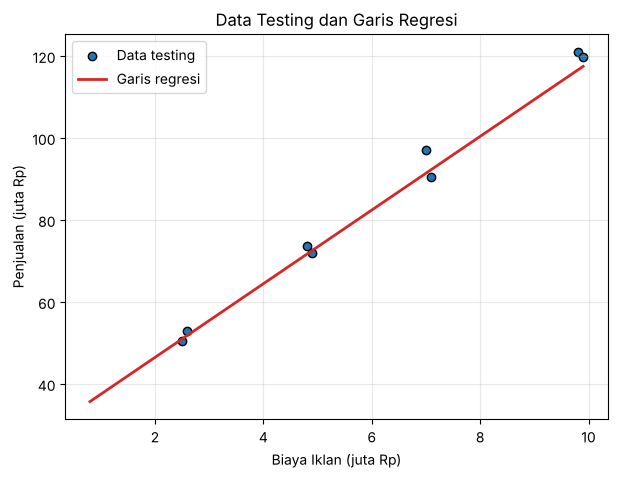

,BiayaIklan (juta),Prediksi Penjualan (juta),Di dalam rentang data?
0,4.5,68.97,True
1,7.0,91.44,True
2,12.0,136.36,False


Rentang BiayaIklan pada data: 0.8 - 9.9


In [8]:
# Jawaban A6
# 1. Scatter data testing + garis regresi (normal equation)
x_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
plt.figure(figsize=(7, 5))
plt.scatter(X_test, y_test, color="tab:blue", edgecolor="k", label="Data testing")
plt.plot(x_line, lin_reg.predict(x_line), color="tab:red", linewidth=2, label="Garis regresi")
plt.title("Data Testing dan Garis Regresi")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 2. Prediksi biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])
pred_baru = lin_reg.predict(biaya_baru)
hasil_prediksi = pd.DataFrame({
    "BiayaIklan (juta)": biaya_baru.ravel(),
    "Prediksi Penjualan (juta)": pred_baru.round(2),
    "Di dalam rentang data?": (biaya_baru.ravel() <= X_ads.max()),
})
display(hasil_prediksi)
print("Rentang BiayaIklan pada data:", X_ads.min(), "-", X_ads.max())

**Jawaban A6 (analisis):**

| Biaya iklan (juta Rp) | Prediksi penjualan (juta Rp) | Di dalam rentang data? |
|---|---|---|
| 4.5 | 68.97 | Ya |
| 7.0 | 91.44 | Ya |
| 12.0 | 136.36 | **Tidak** (data hanya 0,8 – 9,9) |

Prediksi untuk 4,5 juta (68,97 juta Rp) dan 7 juta (91,44 juta Rp) berada di dalam rentang biaya iklan pada data (0,8 – 9,9 juta), sehingga termasuk interpolasi dan lebih masuk akal untuk dipercaya. Meskipun begitu, berada di dalam rentang data **tidak otomatis menjamin prediksi akurat**: model hanya memberikan nilai rata-rata menurut garis lurus, sedangkan penjualan sebenarnya bisa menyimpang dari garis tersebut (RMSE sekitar 6,58 juta pada data training dan 2,87 juta pada data testing), dan model hanya dilatih dari 32 data dengan satu variabel.

Prediksi 12 juta (136,36 juta Rp) adalah **ekstrapolasi** karena 12 juta melampaui batas atas rentang biaya iklan pada data (0,8 – 9,9 juta). Prediksi ini kurang dapat dipercaya. Alasannya:
1. Model tidak pernah melihat data dengan biaya iklan di atas 9,9 juta, jadi tidak ada bukti bahwa hubungan tetap linear di sana.
2. Dalam praktik, efek iklan biasanya mengalami penurunan manfaat (*diminishing returns*) atau jenuh karena pasar terbatas. Garis lurus akan cenderung memprediksi penjualan terlalu tinggi.
3. Model hanya dilatih dari 32 data dan hanya memakai satu variabel, sehingga ketidakpastiannya makin besar semakin jauh dari rentang data.

Hasil tersebut sebaiknya dipakai sebagai perkiraan kasar saja, dan akan lebih baik jika divalidasi dengan data nyata pada tingkat biaya iklan yang lebih tinggi.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 data pertama:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Jumlah baris data: 60

Jumlah email per kelas:
Spam (1)       : 25
Bukan Spam (0) : 35

Shape X: (60, 2) | Shape y: (60,)


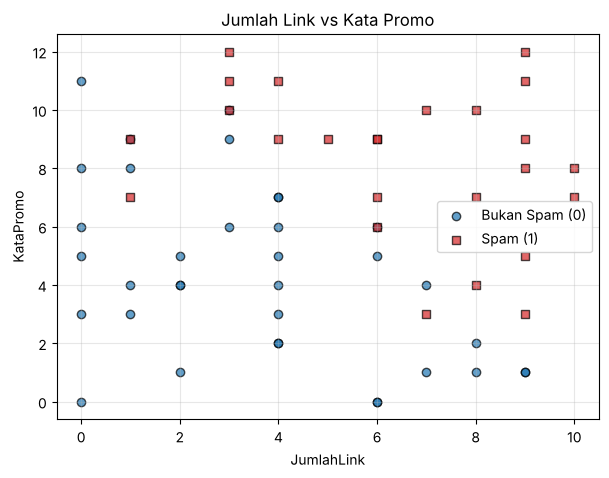

In [9]:
# Jawaban B1
# 1. Baca data
df_email = pd.read_csv("Email_Data.csv")
print("5 data pertama:")
display(df_email.head())
print("Jumlah baris data:", len(df_email))
print("\nJumlah email per kelas:")
print("Spam (1)       :", (df_email["Spam"] == 1).sum())
print("Bukan Spam (0) :", (df_email["Spam"] == 0).sum())

# 2. Pisahkan X dan y
X_mail = df_email[["JumlahLink", "KataPromo"]].values
y_mail = df_email["Spam"].values
print("\nShape X:", X_mail.shape, "| Shape y:", y_mail.shape)

# 3. Scatter plot per kelas
plt.figure(figsize=(7, 5))
plt.scatter(X_mail[y_mail == 0, 0], X_mail[y_mail == 0, 1], c="tab:blue", edgecolor="k",
            alpha=0.7, label="Bukan Spam (0)")
plt.scatter(X_mail[y_mail == 1, 0], X_mail[y_mail == 1, 1], c="tab:red", edgecolor="k",
            alpha=0.7, marker="s", label="Spam (1)")
plt.title("Jumlah Link vs Kata Promo")
plt.xlabel("JumlahLink")
plt.ylabel("KataPromo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Xm_train: (45, 2) | Xm_test: (15, 2)
Jumlah spam di train: 21 dari 45 | di test: 4 dari 15



Intercept (b) : -9.0614
Koefisien m1 (JumlahLink) : 0.8171
Koefisien m2 (KataPromo)  : 0.8041
P(Spam) = sigmoid(-9.0614 + 0.8171 * JumlahLink + 0.8041 * KataPromo)
Log loss awal : 0.6931
Log loss akhir: 0.2890


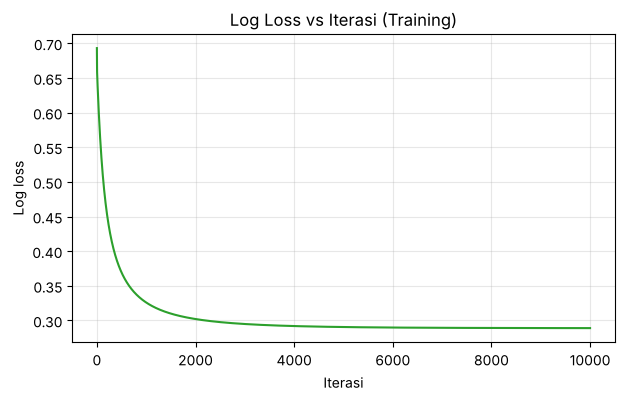

In [10]:
# Jawaban B2
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_mail, y_mail, test_size=0.25, random_state=RANDOM_STATE
)
print("Xm_train:", Xm_train.shape, "| Xm_test:", Xm_test.shape)
print("Jumlah spam di train:", ym_train.sum(), "dari", len(ym_train),
      "| di test:", ym_test.sum(), "dari", len(ym_test))

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_reg.fit(Xm_train, ym_train)

b_log = log_reg.intercept_
m1, m2 = log_reg.coef_
print(f"\nIntercept (b) : {b_log:.4f}")
print(f"Koefisien m1 (JumlahLink) : {m1:.4f}")
print(f"Koefisien m2 (KataPromo)  : {m2:.4f}")
print(f"P(Spam) = sigmoid({b_log:.4f} + {m1:.4f} * JumlahLink + {m2:.4f} * KataPromo)")
print(f"Log loss awal : {log_reg.loss_history_[0]:.4f}")
print(f"Log loss akhir: {log_reg.loss_history_[-1]:.4f}")

# Grafik log loss vs iterasi
plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history_, color="tab:green")
plt.title("Log Loss vs Iterasi (Training)")
plt.xlabel("Iterasi")
plt.ylabel("Log loss")
plt.grid(alpha=0.3)
plt.show()

**Jawaban B2 (analisis):**

- Persamaan model: $P(\text{Spam}) = \sigma(-9.0614 + 0.8171 \cdot \text{JumlahLink} + 0.8041 \cdot \text{KataPromo})$.
- Kedua koefisien bernilai positif: semakin banyak link dan semakin banyak kata promosi dalam email, semakin besar peluang email tersebut spam. Kedua variabel punya pengaruh yang hampir sama kuat ($m_1 \approx m_2$). Setiap tambahan 1 link menaikkan *odds* spam sekitar $e^{0.8171} \approx 2{,}26$ kali, dan tambahan 1 kata promo menaikkannya sekitar $e^{0.8041} \approx 2{,}23$ kali.
- Data dibagi menjadi 45 data training dan 15 data testing. Data testing hanya berisi 4 email spam, sehingga metrik pada data testing akan mudah berubah dengan sedikit saja perubahan prediksi.
- **Grafik log loss:** loss dimulai dari 0,6931 (nilai $\ln 2$, saat model menebak 0,5 untuk semua data), turun cepat pada ± 1000 iterasi pertama, lalu melandai hingga 0,2890 pada iterasi ke-10000. Pada grafik terlihat loss sudah **turun dan stabil** (mendatar) di akhir training, sehingga gradient descent sudah konvergen.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [11]:
# Jawaban B3
def precision_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fp = cm[1, 1], cm[0, 1]
    return tp / (tp + fp) if (tp + fp) > 0 else 0.0

def recall_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tp, fn = cm[1, 1], cm[1, 0]
    return tp / (tp + fn) if (tp + fn) > 0 else 0.0

def f1_score(y_true, y_pred):
    p = precision_score(y_true, y_pred)
    r = recall_score(y_true, y_pred)
    return 2 * p * r / (p + r) if (p + r) > 0 else 0.0

ym_pred = log_reg.predict(Xm_test)           # threshold 0.5
cm = confusion_matrix(ym_test, ym_pred)

print(f"Accuracy  : {accuracy_score(ym_test, ym_pred):.4f}")
print(f"Precision : {precision_score(ym_test, ym_pred):.4f}")
print(f"Recall    : {recall_score(ym_test, ym_pred):.4f}")
print(f"F1-score  : {f1_score(ym_test, ym_pred):.4f}")
print("\nConfusion matrix (baris = aktual, kolom = prediksi):")
display(pd.DataFrame(cm, index=["Aktual Bukan Spam", "Aktual Spam"],
                     columns=["Prediksi Bukan Spam", "Prediksi Spam"]))
print(f"TN = {cm[0,0]}, FP = {cm[0,1]}, FN = {cm[1,0]}, TP = {cm[1,1]}")

Accuracy  : 0.9333
Precision : 0.8000
Recall    : 1.0000
F1-score  : 0.8889

Confusion matrix (baris = aktual, kolom = prediksi):


,Prediksi Bukan Spam,Prediksi Spam
Aktual Bukan Spam,10,1
Aktual Spam,0,4


TN = 10, FP = 1, FN = 0, TP = 4


**Jawaban B3 (analisis):**

Hasil pada data testing (threshold 0,5, 15 email):

| Metrik | Nilai |
|---|---|
| Accuracy | 0.9333 |
| Precision | 0.8000 |
| Recall | 1.0000 |
| F1-score | 0.8889 |

Confusion matrix: TN = 10, FP = 1, FN = 0, TP = 4.

- **False Positive (FP)**: email yang sebenarnya *bukan spam* tetapi diprediksi *spam*. Pada data ini FP = 1.
- **False Negative (FN)**: email yang sebenarnya *spam* tetapi diprediksi *bukan spam* sehingga lolos ke inbox. Pada data ini FN = 0, sehingga semua spam berhasil terdeteksi (recall 100%).
- **Kesalahan yang lebih merugikan: FP.** Email normal yang masuk ke folder spam bisa tidak terbaca, padahal mungkin penting (misalnya undangan wawancara, tagihan, atau email dosen). Sebaliknya, FN hanya membuat satu email spam muncul di inbox, yang cukup dihapus manual dan dampaknya kecil. Karena itu filter spam sebaiknya menjaga **precision** tetap tinggi.
- Catatan: dengan hanya 15 data testing (4 spam), satu kesalahan saja sudah menurunkan precision menjadi 0,80, jadi angka ini belum bisa dianggap sangat stabil.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-9.0614 + 0.8171 * JumlahLink) / 0.8041
                   KataPromo = 11.2693 + -1.0162 * JumlahLink


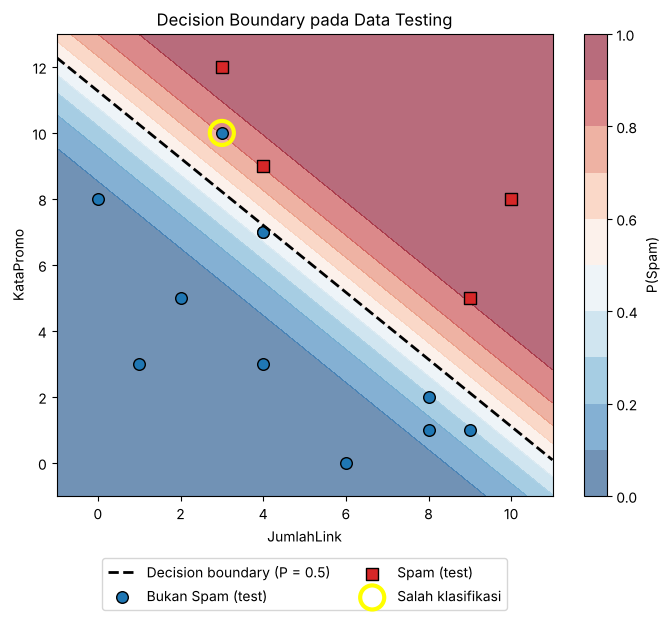

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Aktual,Prediksi,P(Spam)
0,3,10,0,1,0.807


In [12]:
# Jawaban B4
# 1. Persamaan decision boundary: x2 = -(b + m1*x1) / m2
print(f"Decision boundary: KataPromo = -({b_log:.4f} + {m1:.4f} * JumlahLink) / {m2:.4f}")
print(f"                   KataPromo = {-b_log/m2:.4f} + {-m1/m2:.4f} * JumlahLink")

# 2. Visualisasi: background probabilitas + garis boundary + data testing
x1_min, x1_max = X_mail[:, 0].min() - 1, X_mail[:, 0].max() + 1
x2_min, x2_max = X_mail[:, 1].min() - 1, X_mail[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300), np.linspace(x2_min, x2_max, 300))
grid = np.c_[xx1.ravel(), xx2.ravel()]
prob_grid = log_reg.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
cs = plt.contourf(xx1, xx2, prob_grid, levels=np.linspace(0, 1, 11), cmap="RdBu_r", alpha=0.6)
plt.colorbar(cs, label="P(Spam)")

x1_line = np.linspace(x1_min, x1_max, 100)
x2_line = -(b_log + m1 * x1_line) / m2
plt.plot(x1_line, x2_line, "k--", linewidth=2, label="Decision boundary (P = 0.5)")

plt.scatter(Xm_test[ym_test == 0, 0], Xm_test[ym_test == 0, 1], c="tab:blue", edgecolor="k",
            s=70, label="Bukan Spam (test)")
plt.scatter(Xm_test[ym_test == 1, 0], Xm_test[ym_test == 1, 1], c="tab:red", edgecolor="k",
            s=70, marker="s", label="Spam (test)")

# 3. Tandai data yang salah diklasifikasikan
salah = ym_pred != ym_test
plt.scatter(Xm_test[salah, 0], Xm_test[salah, 1], s=300, facecolors="none",
            edgecolors="yellow", linewidths=3, label="Salah klasifikasi")
plt.xlim(x1_min, x1_max); plt.ylim(x2_min, x2_max)
plt.title("Decision Boundary pada Data Testing")
plt.xlabel("JumlahLink"); plt.ylabel("KataPromo")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
plt.show()

print("Data testing yang salah diklasifikasikan:")
display(pd.DataFrame({
    "JumlahLink": Xm_test[salah, 0],
    "KataPromo": Xm_test[salah, 1],
    "Aktual": ym_test[salah],
    "Prediksi": ym_pred[salah],
    "P(Spam)": log_reg.predict_proba(Xm_test[salah]).round(3),
}))

**Jawaban B4 (analisis):**

- Decision boundary: $x_2 = -\dfrac{-9.0614 + 0.8171\,x_1}{0.8041} = 11.2693 - 1.0162\,x_1$, dengan $x_1$ = JumlahLink dan $x_2$ = KataPromo. Titik di atas garis diprediksi spam, titik di bawah garis diprediksi bukan spam. Garisnya bergerak turun dengan kemiringan sekitar $-1$, artinya jumlah link dan jumlah kata promo kira-kira "saling menggantikan": email dengan total (link + kata promo) sekitar 11 berada tepat di batas.
- Pada grafik, daerah merah di kanan atas adalah daerah probabilitas spam tinggi, daerah biru di kiri bawah adalah probabilitas spam rendah, dan zona putih sekitar garis adalah zona ketidakpastian (P ≈ 0,5).
- **Data yang salah klasifikasi (dilingkari kuning): 1 email**, yaitu JumlahLink = 3 dan KataPromo = 10. Aslinya bukan spam, tetapi diprediksi spam dengan P(Spam) = 0,807 (termasuk FP). Titik ini berada di sisi spam dari garis karena 10 lebih besar daripada nilai batas pada JumlahLink = 3 (sekitar 8,2).
- Kesalahan ini sulit dihindari oleh model linear mana pun: pada dataset terdapat dua email dengan nilai fitur yang sama persis (JumlahLink = 3, KataPromo = 10), yang satu berlabel spam dan yang satu bukan. Dua data dengan fitur sama tetapi label berbeda tidak mungkin diklasifikasikan benar semuanya (adanya *noise* pada label).

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [13]:
# Jawaban B5
proba_test = log_reg.predict_proba(Xm_test)

rows = []
for th in [0.3, 0.5, 0.7]:
    pred = (proba_test >= th).astype(int)
    cm_th = confusion_matrix(ym_test, pred)
    rows.append({
        "Threshold": th,
        "TN": cm_th[0, 0], "FP": cm_th[0, 1], "FN": cm_th[1, 0], "TP": cm_th[1, 1],
        "Accuracy": accuracy_score(ym_test, pred),
        "Precision": precision_score(ym_test, pred),
        "Recall": recall_score(ym_test, pred),
    })
tabel_threshold = pd.DataFrame(rows).set_index("Threshold")
display(tabel_threshold.round(4))

,TN,FP,FN,TP,Accuracy,Precision,Recall
Threshold,,,,,,,
0.3,8,3,0,4,0.8000,0.5714,1.0
0.5,10,1,0,4,0.9333,0.8000,1.0
0.7,10,1,0,4,0.9333,0.8000,1.0


**Jawaban B5 (analisis):**

| Threshold | TN | FP | FN | TP | Accuracy | Precision | Recall |
|---|---|---|---|---|---|---|---|
| 0.3 | 8 | 3 | 0 | 4 | 0.8000 | 0.5714 | 1.0 |
| 0.5 | 10 | 1 | 0 | 4 | 0.9333 | 0.8000 | 1.0 |
| 0.7 | 10 | 1 | 0 | 4 | 0.9333 | 0.8000 | 1.0 |

- **Pengaruh threshold:** menurunkan threshold membuat model lebih mudah menyebut email sebagai spam. Recall naik atau tetap, tetapi FP bertambah sehingga precision turun. Pada threshold 0,3 terdapat 3 FP dan precision turun menjadi 0,5714. Menaikkan threshold bekerja sebaliknya: model lebih ketat, FP berkurang dan precision naik, tetapi risiko spam yang lolos (FN) bertambah sehingga recall bisa turun.
- Pada data testing ini recall tetap 1,0 di semua threshold karena keempat email spam mempunyai probabilitas yang tinggi. Hasil threshold 0,5 dan 0,7 sama persis karena satu-satunya FP memiliki P = 0,807, masih di atas 0,7, dan tidak ada spam yang probabilitasnya antara 0,5 dan 0,7.
- **Threshold yang saya pilih: 0,7.** Berdasarkan Soal B3, FP (email penting masuk ke spam) lebih merugikan daripada FN, sehingga filter sebaiknya lebih berhati-hati dan hanya memblokir email jika model cukup yakin. Perlu dicatat bahwa pada data testing yang tersedia, **keunggulan 0,7 terhadap 0,5 belum terlihat**: confusion matrix, precision, dan recall keduanya identik (FP = 1, FN = 0). Jadi pemilihan 0,7 didasarkan pada pertimbangan biaya kesalahan (FP lebih merugikan), bukan pada bukti dari hasil eksperimen ini. Threshold 0,7 juga tidak menurunkan recall dibandingkan 0,5, sehingga tidak ada biaya yang terlihat pada data ini. Saya tidak memilih threshold yang lebih tinggi lagi karena risiko FN akan bertambah. Karena data testing kecil (15 email, 4 spam), pilihan ini sebaiknya dikonfirmasi lagi pada data yang lebih banyak.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5, yaitu **0,7**):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [14]:
# Jawaban B6
THRESHOLD_PILIHAN = 0.7   # threshold pilihan dari Soal B5 (lihat alasan di analisis B5)

email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11],
})
proba_baru = log_reg.predict_proba(email_baru[["JumlahLink", "KataPromo"]].values)
email_baru["P(Spam)"] = proba_baru.round(4)
email_baru["Prediksi"] = np.where(proba_baru >= THRESHOLD_PILIHAN, "Spam", "Bukan Spam")
display(email_baru)

,Email,JumlahLink,KataPromo,P(Spam),Prediksi
0,E1,1,2,0.0013,Bukan Spam
1,E2,5,6,0.4622,Bukan Spam
2,E3,9,10,0.9982,Spam
3,E4,2,11,0.8050,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression termasuk klasifikasi karena keluarannya adalah peluang suatu data masuk kelas tertentu (misalnya P(Spam)), yang kemudian diubah menjadi label 0/1 dengan threshold, bukan nilai kontinu yang bebas. Kata "regression" hanya berasal dari proses di dalamnya, yaitu menghitung kombinasi linear $z = b + m_1x_1 + m_2x_2$ seperti pada regresi linear. Fungsi **sigmoid** $\sigma(z) = 1/(1+e^{-z})$ menekan $z$ yang bisa bernilai berapa saja menjadi angka di antara 0 dan 1 sehingga dapat dibaca sebagai probabilitas. Pada tugas ini, misalnya, email E3 mendapat $z$ yang besar sehingga P(Spam) = 0,9982, sedangkan E1 mendapat $z$ yang sangat negatif sehingga P(Spam) = 0,0013.

**Jawaban C2:**
Normal equation menghitung parameter optimal langsung dalam satu kali perhitungan ($\theta = (X^TX)^{-1}X^Ty$), tanpa learning rate dan tanpa iterasi, tetapi harus membalik matriks yang mahal ($O(d^3)$) dan bisa tidak stabil jika fitur sangat banyak atau saling berkorelasi. Gradient descent memperbaiki parameter sedikit demi sedikit mengikuti arah turunnya loss, sehingga harus memilih learning rate dan jumlah iterasi (Soal A5: lr 0,1 divergen, lr 0,001 terlalu lambat, lr 0,02 hasilnya sama dengan normal equation). Gradient descent sebaiknya dipakai ketika jumlah fitur atau data sangat besar, atau ketika model tidak punya solusi tertutup, misalnya Logistic Regression dan jaringan saraf. Untuk data kecil dengan satu fitur seperti `Ads_Data.csv`, normal equation sudah cukup.

**Jawaban C3:**
Model dilatih untuk menyesuaikan diri dengan data training, sehingga skor pada data training cenderung terlalu optimis, dan kemampuan pada data baru hanya bisa diukur dengan data testing. **Overfitting** terjadi ketika model terlalu menghafal data training, termasuk noise-nya, sehingga skor training sangat bagus tetapi skor testing jauh lebih buruk. Pada tugas ini R² testing (0,9873) justru lebih tinggi daripada R² training (0,9276), tetapi hal itu tidak dengan sendirinya membuktikan bahwa model bebas dari overfitting. Dengan 32 data training dan hanya 8 data testing, skor testing sangat bergantung pada titik yang kebetulan terpilih (di sini titik testing kebetulan dekat dengan garis), sehingga evaluasinya kurang stabil. Yang dapat disimpulkan hanyalah bahwa tidak terlihat tanda overfitting yang jelas, sedangkan kesimpulan yang lebih kuat membutuhkan data lebih banyak atau evaluasi dengan beberapa pembagian data.

**Jawaban C4:**
Linear Regression menghasilkan nilai kontinu (penjualan dalam juta Rp), sehingga cara wajar mengukur kesalahannya adalah selisih kuadrat antara nilai prediksi dan nilai sebenarnya, yaitu MSE. Logistic Regression menghasilkan probabilitas dan targetnya hanya 0 atau 1, sehingga loss yang cocok adalah log loss (cross-entropy), yang berasal dari prinsip *maximum likelihood* untuk data Bernoulli. Log loss memberi hukuman sangat besar jika model sangat yakin tetapi salah (misal memprediksi P = 0,99 padahal label 0), dan menghasilkan fungsi loss konveks dengan gradien sederhana ($p - y$). Jika MSE dipakai bersama sigmoid, loss menjadi tidak konveks dan gradiennya sangat kecil ketika prediksi salah tapi sudah jenuh, sehingga training lambat dan bisa terjebak.

**Jawaban C5:**
Dataset dan algoritmanya sama, tetapi `random_state` setiap mahasiswa berbeda (dua digit terakhir NIM), sehingga data training dan testing yang terpilih juga berbeda. Model dilatih pada subset data yang berbeda, jadi koefisien, intercept, dan metrik evaluasinya ikut berbeda. Dengan dataset sekecil ini (40 dan 60 baris), satu atau dua data yang pindah antara training dan testing sudah cukup menggeser hasil. Misalnya pada tugas ini, data testing hanya 8 titik (regresi) dan 15 email dengan 4 spam (klasifikasi). Selain itu, pilihan seperti learning rate dan jumlah iterasi juga memengaruhi hasil jika berbeda.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [15]:
# Jawaban Bonus
from sklearn.linear_model import LinearRegression as SkLinearRegression
from sklearn.linear_model import LogisticRegression as SkLogisticRegression

# --- Linear Regression ---
sk_lin = SkLinearRegression().fit(X_train, y_train)
print("=== Linear Regression ===")
print(f"Implementasi sendiri : intercept = {b_ne:.6f}, koef = {m_ne:.6f}")
print(f"scikit-learn         : intercept = {sk_lin.intercept_:.6f}, koef = {sk_lin.coef_[0]:.6f}")
print(f"R2 test (sendiri)    : {r2_score(y_test, y_pred_test):.6f}")
print(f"R2 test (sklearn)    : {r2_score(y_test, sk_lin.predict(X_test)):.6f}")

# --- Logistic Regression ---
sk_log_default = SkLogisticRegression().fit(Xm_train, ym_train)                  # default: penalty L2, C=1.0
sk_log_nopen = SkLogisticRegression(C=np.inf, max_iter=10000).fit(Xm_train, ym_train)     # C=inf -> tanpa regularisasi (setara penalty=None)

def log_loss(y_true, p, eps=1e-15):
    return -np.mean(y_true * np.log(p + eps) + (1 - y_true) * np.log(1 - p + eps))

def ringkas(nama, b, m, pred):
    p_train = sigmoid(b + Xm_train @ m)
    return {"Model": nama, "b": b, "m1 (Link)": m[0], "m2 (Promo)": m[1],
            "LogLoss train": log_loss(ym_train, p_train),
            "Accuracy": accuracy_score(ym_test, pred),
            "Precision": precision_score(ym_test, pred),
            "Recall": recall_score(ym_test, pred)}

tabel_bonus = pd.DataFrame([
    ringkas("Sendiri (tanpa regularisasi)", b_log, log_reg.coef_, ym_pred),
    ringkas("sklearn default (L2, C=1.0)", sk_log_default.intercept_[0], sk_log_default.coef_[0],
            sk_log_default.predict(Xm_test)),
    ringkas("sklearn C=inf (tanpa penalti)", sk_log_nopen.intercept_[0], sk_log_nopen.coef_[0],
            sk_log_nopen.predict(Xm_test)),
]).set_index("Model")
print("\n=== Logistic Regression ===")
display(tabel_bonus.round(4))

=== Linear Regression ===
Implementasi sendiri : intercept = 28.540483, koef = 8.985056
scikit-learn         : intercept = 28.540483, koef = 8.985056
R2 test (sendiri)    : 0.987297
R2 test (sklearn)    : 0.987297

=== Logistic Regression ===


,b,m1 (Link),m2 (Promo),LogLoss train,Accuracy,Precision,Recall
Model,,,,,,,
Sendiri (tanpa regularisasi),-9.0614,0.8171,0.8041,0.2890,0.9333,0.8,1.0
"sklearn default (L2, C=1.0)",-8.3354,0.7485,0.7396,0.2903,0.9333,0.8,1.0
sklearn C=inf (tanpa penalti),-9.3576,0.8433,0.8300,0.2889,0.9333,0.8,1.0


**Jawaban Bonus (analisis):**

**Linear Regression.** Intercept (28,540483), koefisien (8,985056), dan R² testing (0,987297) dari implementasi saya sama persis dengan scikit-learn sampai 6 angka desimal. Hal ini wajar karena keduanya menyelesaikan masalah kuadrat terkecil yang sama dengan solusi tertutup (*closed form*), sehingga tidak ada perbedaan.

**Logistic Regression.** Koefisien berbeda cukup jelas:

| Model | b | m1 (Link) | m2 (Promo) | Log loss train |
|---|---|---|---|---|
| Implementasi sendiri (tanpa regularisasi) | -9.0614 | 0.8171 | 0.8041 | 0.2890 |
| sklearn default (L2, C=1.0) | -8.3354 | 0.7485 | 0.7396 | 0.2903 |
| sklearn C=inf (tanpa penalti) | -9.3576 | 0.8433 | 0.8300 | 0.2889 |

- **Penyebab utama:** `LogisticRegression` di scikit-learn secara default memakai **regularisasi L2 dengan C = 1,0**. Regularisasi memberi penalti pada besarnya koefisien sehingga koefisien "ditarik" mendekati nol (semua koefisien memiliki nilai absolut lebih kecil daripada milik saya). Implementasi saya dari materi tidak memakai penalti sama sekali.
- Ketika regularisasi dimatikan (`C=np.inf`, setara dengan `penalty=None`), koefisien sklearn (-9,3576; 0,8433; 0,8300) menjadi jauh lebih dekat ke milik saya, tetapi masih sedikit berbeda. Perbedaan kecil ini kemungkinan besar muncul karena sklearn memakai *solver* lain (lbfgs) yang mencari solusi optimum sampai konvergen, sedangkan gradient descent saya berhenti pada 10.000 iterasi. Pada kurva loss, bagian akhirnya sangat datar sehingga parameter bisa masih bergeser pelan-pelan. Log loss training-nya hampir sama (0,2890 vs 0,2889), jadi perbedaan ini sangat kecil.
- **Dampak pada evaluasi:** accuracy (0,9333), precision (0,80), dan recall (1,0) pada data testing sama untuk ketiga model. Perbedaan koefisien hanya menggeser garis decision boundary sedikit, dan pada data testing yang tersedia perbedaan tersebut tidak terlihat pada hasil evaluasi.